# Daily Challenge — Pokemon Win Prediction Analysis

In this challenge, I clean the Pokemon and combats data, calculate each Pokemon’s win percentage, explore how the stats relate to winning, and I train regression models to predict the win percentage.

**What I learn here**
- Data cleaning and handling missing values.
- Exploratory Data Analysis (EDA) with visualization tools like Seaborn and Matplotlib.
- Feature engineering and correlation analysis.
- Building and comparing regression models (Linear Regression, SVM, Decision Trees, etc.).
- Dimensionality reduction using PCA.

**What I will create**
- A cleaned Pokemon dataset with engineered features (for example, win percentage).
- Visualizations to analyze Pokemon stats and battle outcomes.
- A machine learning model to predict Pokemon win percentages.

**Dataset**

The course zip is [Pokemon Data Analysis Tutorial.zip](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%205/Day%204%20-%20Statistics%20for%20Machine%20Learning/Pokemon%20Data%20Analysis%20Tutorial.zip):

- `pokemon.csv`: Contains stats like HP, Attack, Type 1, Legendary, etc., for 800+ Pokemon.
- `combats.csv`: Records 50,000 battle outcomes between Pokemon.

**Structure**
1. Data Preparation
2. Exploratory Analysis and Visualization
3. Machine Learning

## How to run in Colab
1. I open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** and choose this file.
2. I keep the course dataset zip **`Pokemon Data Analysis Tutorial.zip`** in my `C:\Users\sivan\Datasets` folder (I don't unzip it myself). I downloaded it from the [course GitHub](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%205/Day%204%20-%20Statistics%20for%20Machine%20Learning/Pokemon%20Data%20Analysis%20Tutorial.zip).
3. I run the cells from top to bottom. When the upload cell opens a file picker, I choose `Pokemon Data Analysis Tutorial.zip`. The next line unzips it and gives me **`pokemon.csv`** and **`combats.csv`** inside the folder `Pokemon Data Analysis Tutorial`. (The zip also has `tests.csv`, which this challenge does not use.)

(If I run the notebook on my own computer instead of Colab, the upload step is skipped and the zip just needs to be in the same folder as the notebook.)

In [1]:
try:
    from google.colab import files
    uploaded = files.upload()  # Prompts user to select zip file
except ImportError:
    print("Not running in Colab: I use the zip that is already next to this notebook.")
!unzip -o "Pokemon Data Analysis Tutorial.zip"     # Unzips uploaded dataset file

Not running in Colab: I use the zip that is already next to this notebook.
Archive:  Pokemon Data Analysis Tutorial.zip
  inflating: Pokemon Data Analysis Tutorial/combats.csv  
  inflating: Pokemon Data Analysis Tutorial/pokemon.csv  
  inflating: Pokemon Data Analysis Tutorial/tests.csv  


In [2]:
import pandas as pd
# pandas for the tables
import numpy as np
# numpy for number calculations
import matplotlib.pyplot as plt
# matplotlib for charts
import seaborn as sns
# seaborn for the correlation heatmap, pairplot and PairGrid
from sklearn.model_selection import train_test_split
# I will use this for the 80/20 train/test split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
# I compare the models with Mean Absolute Error (MAE)

## 1. Data Preparation

- Load and merge `pokemon.csv` and `combats.csv`.
- Fix missing values:
  - Fill the missing Name for Pokemon #62 (Primeape).
  - Handle NaN values in Type 2 (mark as “None” if missing).
- Calculate each Pokemon’s win percentage using the combat data.

### 1.1 Load and merge the data

I load `pokemon.csv` and `combats.csv` from the folder `Pokemon Data Analysis Tutorial`, and I merge them.

In [3]:
folder = "Pokemon Data Analysis Tutorial"
# after unzipping, the files are in this folder
pokemon = pd.read_csv(f"{folder}/pokemon.csv")
combats = pd.read_csv(f"{folder}/combats.csv")

print("pokemon:", pokemon.shape)
print("combats:", combats.shape)
pokemon.head()

pokemon: (800, 12)
combats: (50000, 3)


,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


**What I see:** `pokemon.csv` has **800 Pokemon and 12 columns** (id `#`, name, types, the six battle stats, generation and Legendary), and `combats.csv` has **50,000 battles**. I can already see an empty `Type 2` for Charmander, because it has only one type.

In [4]:
combats.head()
# each row is one battle: the id (#) of the first Pokemon, the id of the second Pokemon, and the id of the winner

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


**What I see:** the combats table only has ids, no names. To read it, I merge it with the Pokemon table.

In [5]:
def add_names(combats, pokemon):
    """I merge the combats with the Pokemon table so every id gets its Pokemon name."""
    names = pokemon[["#", "Name"]]
    merged = combats.merge(names.rename(columns={"#": "First_pokemon", "Name": "First_name"}), on="First_pokemon", how="left")
    merged = merged.merge(names.rename(columns={"#": "Second_pokemon", "Name": "Second_name"}), on="Second_pokemon", how="left")
    merged = merged.merge(names.rename(columns={"#": "Winner", "Name": "Winner_name"}), on="Winner", how="left")
    return merged

battles = add_names(combats, pokemon)
print("Merged shape:", battles.shape)
print("Battles where the winner is not one of the two fighters:",
      ((battles["Winner"] != battles["First_pokemon"]) & (battles["Winner"] != battles["Second_pokemon"])).sum())
battles.head()

Merged shape: (50000, 6)
Battles where the winner is not one of the two fighters: 0


,First_pokemon,Second_pokemon,Winner,First_name,Second_name,Winner_name
0,266,298,298,Larvitar,Nuzleaf,Nuzleaf
1,702,701,701,Virizion,Terrakion,Terrakion
2,191,668,668,Togetic,Beheeyem,Beheeyem
3,237,683,683,Slugma,Druddigon,Druddigon
4,151,231,151,Omastar,Shuckle,Omastar


**What I see:** after the merge, every battle has the names of both fighters and of the winner (still 50,000 rows). I also checked that the winner is always one of the two fighters: there are 0 broken rows.

### 1.2 Fix missing values

I fill the missing Name for Pokemon #62 (Primeape), and I mark missing Type 2 values as “None”.

In [6]:
print(pokemon.isna().sum())
# I count the empty values in every column of pokemon.csv

#               0
Name            1
Type 1          0
Type 2        386
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64


**What I see:** only two columns have missing values: `Name` (1 missing) and `Type 2` (386 missing).

In [7]:
print(pokemon[pokemon["Name"].isna()])
# which row has no name?
print()
print(pokemon.loc[60:64, ["#", "Name", "Type 1", "Type 2", "HP", "Attack", "Speed"]])
# I look at the rows around it to see where it sits

     # Name    Type 1 Type 2  HP  Attack  Defense  Sp. Atk  Sp. Def  Speed  \
62  63  NaN  Fighting    NaN  65     105       60       60       70     95   

    Generation  Legendary  
62           1      False  

     #       Name    Type 1 Type 2  HP  Attack  Speed
60  61    Golduck     Water    NaN  80      82     85
61  62     Mankey  Fighting    NaN  40      80     70
62  63        NaN  Fighting    NaN  65     105     95
63  64  Growlithe      Fire    NaN  55      70     60
64  65   Arcanine      Fire    NaN  90     110     95


**What I see (checking the brief):** the brief says the missing name is Pokemon #62. In this file, the row with the empty name is at **index 62** (the 63rd row), and its `#` column is **63**, while `#` 62 is Mankey. So the brief counts from 0 (the pandas index), not the `#` column. It is the right Pokemon either way: it comes right after Mankey, it is a Fighting type with higher stats than Mankey, and Primeape is what Mankey evolves into. So I fill this row with **Primeape**.

In [8]:
pokemon.loc[pokemon["Name"].isna(), "Name"] = "Primeape"
# I fill the one missing Name with Primeape, as the brief says
pokemon["Type 2"] = pokemon["Type 2"].fillna("None")
# Pokemon with only one type have no Type 2, so I mark it as the text "None"

print(pokemon.loc[60:64, ["#", "Name", "Type 1", "Type 2"]])
print()
print("Missing values left:", pokemon.isna().sum().sum())

battles = add_names(combats, pokemon)
# I redo the merge so the battles table also has the name Primeape
print("Missing names in the merged battles:", battles[["First_name", "Second_name", "Winner_name"]].isna().sum().sum())

     #       Name    Type 1 Type 2
60  61    Golduck     Water   None
61  62     Mankey  Fighting   None
62  63   Primeape  Fighting   None
63  64  Growlithe      Fire   None
64  65   Arcanine      Fire   None

Missing values left: 0
Missing names in the merged battles: 0


**What I see:** the row with `#` 63 is now Primeape, single-type Pokemon now have `Type 2` = "None", and there are 0 missing values left in the Pokemon table and 0 missing names in the merged battles.

### 1.3 Calculate each Pokemon’s win percentage

I use the combat data to calculate each Pokemon’s win percentage.

In [9]:
wins = combats["Winner"].value_counts()
# how many times each Pokemon won
fights = combats["First_pokemon"].value_counts().add(combats["Second_pokemon"].value_counts(), fill_value=0)
# how many fights each Pokemon had (as the first OR the second fighter)

pokemon["Total Fights"] = pokemon["#"].map(fights)
pokemon["Wins"] = pokemon["#"].map(wins)
pokemon.loc[pokemon["Total Fights"].notna() & pokemon["Wins"].isna(), "Wins"] = 0
# a Pokemon that fought but never won has 0 wins (not empty)
pokemon["Win Percentage"] = pokemon["Wins"] / pokemon["Total Fights"] * 100
# win percentage = wins / total fights, times 100 so it reads as a percent (0-100)

print("Pokemon that fought at least once:", pokemon["Total Fights"].notna().sum())
print("Pokemon that never fought:", pokemon["Total Fights"].isna().sum())
print("Pokemon that fought but never won:", (pokemon["Wins"] == 0).sum())
print()
print(pokemon["Total Fights"].describe().round(1))
print()
print(pokemon["Win Percentage"].describe().round(2))

Pokemon that fought at least once: 784
Pokemon that never fought: 16
Pokemon that fought but never won: 1

count    784.0
mean     127.6
std       11.4
min       92.0
25%      120.0
50%      128.0
75%      135.0
max      164.0
Name: Total Fights, dtype: float64

count    784.00
mean      50.09
std       25.55
min        0.00
25%       28.37
50%       49.09
75%       71.74
max       98.45
Name: Win Percentage, dtype: float64


**What I see:** 784 Pokemon fought at least once, and each of them had between 92 and 164 fights (about 128 on average), which is enough to trust their win percentage. **16 Pokemon never fought**. One Pokemon fought but never won, so its win percentage is 0%. The win percentage goes from 0% to 98.45%, with a mean of about 50%, which makes sense because every battle has one winner and one loser.

In [10]:
print(pokemon[pokemon["Total Fights"].isna()][["#", "Name", "Type 1", "Legendary"]])
# these Pokemon have no battles, so I cannot calculate a win percentage for them

       #                  Name    Type 1  Legendary
11    12             Blastoise     Water      False
32    33             Sandshrew    Ground      False
45    46            Wigglytuff    Normal      False
65    66               Poliwag     Water      False
77    78            Victreebel     Grass      False
89    90              Magneton  Electric      False
143  144                 Ditto    Normal      False
182  183               Ariados       Bug      False
235  236              Ursaring    Normal      False
321  322              Hariyama  Fighting      False
418  419           Mega Latias    Dragon       True
478  479             Honchkrow      Dark      False
555  556               Servine     Grass      False
617  618              Maractus     Grass      False
654  655             Jellicent     Water      False
781  782  Pumpkaboo Small Size     Ghost      False


**What I see:** these 16 Pokemon (for example Blastoise, Ditto and Mega Latias) do not appear in `combats.csv` at all. Their win percentage is not 0%, it is unknown.

Clean dataset for the analysis: (784, 15)


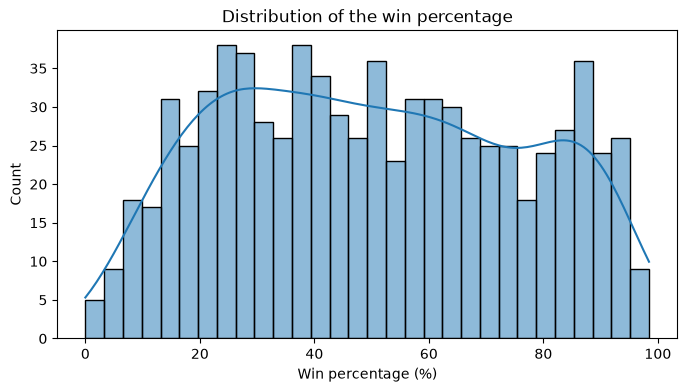

In [11]:
df = pokemon.dropna(subset=["Win Percentage"]).copy()
# For the analysis and the model I keep only the Pokemon with a real win percentage.
# I don't put 0% for the ones that never fought, because 0% would mean "lost every fight", which is not true.
print("Clean dataset for the analysis:", df.shape)

plt.figure(figsize=(8, 4))
sns.histplot(df["Win Percentage"], bins=30, kde=True)
plt.title("Distribution of the win percentage")
plt.xlabel("Win percentage (%)")
plt.show()

**What I see:** I keep the 784 Pokemon that fought. The win percentages are spread over the whole range from 0% to almost 100%, so there are clearly strong and weak Pokemon.

## 2. Exploratory Analysis and Visualization

- Create a correlation matrix to identify relationships between stats (HP, Attack, Speed) and win percentage.
- Plot a Seaborn pairplot or PairGrid for stats vs. win percentage.
- Analyze the top 10 Pokemon by win percentage and their stats.

### 2.1 Correlation matrix

I create a correlation matrix to identify relationships between stats (HP, Attack, Speed) and win percentage.

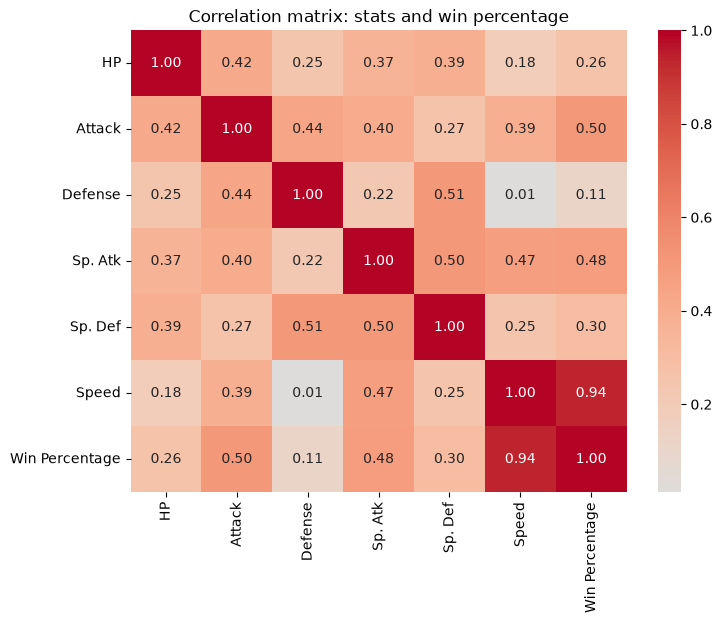

Correlation of each stat with the win percentage:
Speed      0.938
Attack     0.503
Sp. Atk    0.481
Sp. Def    0.302
HP         0.262
Defense    0.115
Name: Win Percentage, dtype: float64


In [12]:
stats = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
corr = df[stats + ["Win Percentage"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: stats and win percentage")
plt.show()

print("Correlation of each stat with the win percentage:")
print(corr["Win Percentage"].drop("Win Percentage").sort_values(ascending=False).round(3))

**What I see:** **Speed** has by far the strongest relationship with the win percentage (**0.938**). Attack (0.503) and Sp. Atk (0.481) come next, then Sp. Def (0.302) and HP (0.262). Defense is almost unrelated (0.115). So the Pokemon that win are mostly the fast ones.

### 2.2 Pairplot or PairGrid

I plot a Seaborn pairplot or PairGrid for the stats vs. win percentage.

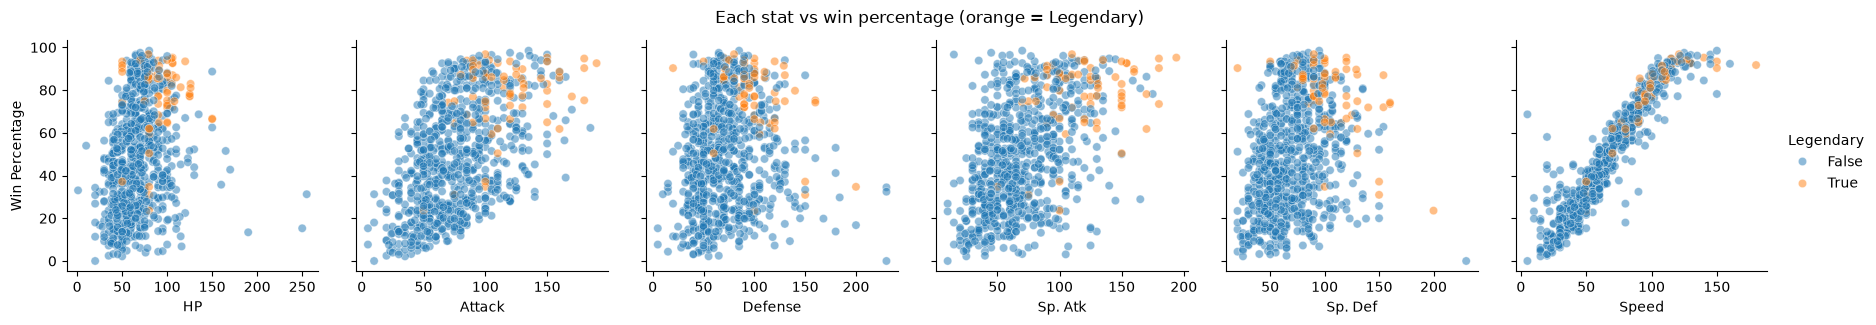

Average win percentage by Legendary:
Legendary
False    47.6
True     77.9
Name: Win Percentage, dtype: float64


In [13]:
g = sns.PairGrid(df, x_vars=stats, y_vars=["Win Percentage"], hue="Legendary", height=3)
g.map(sns.scatterplot, alpha=0.5)
g.add_legend()
g.fig.suptitle("Each stat vs win percentage (orange = Legendary)", y=1.05)
plt.show()
# one row of plots: every stat on the x axis, the win percentage on the y axis

print("Average win percentage by Legendary:")
print(df.groupby("Legendary")["Win Percentage"].mean().round(1))

**What I see:** the Speed plot is almost a straight rising line, which matches the 0.938 correlation. The other stats are much more spread out, with only a slow upward trend for Attack and Sp. Atk. The orange (Legendary) Pokemon are mostly at the top: on average they win 77.9% of their fights, against 47.6% for the others.

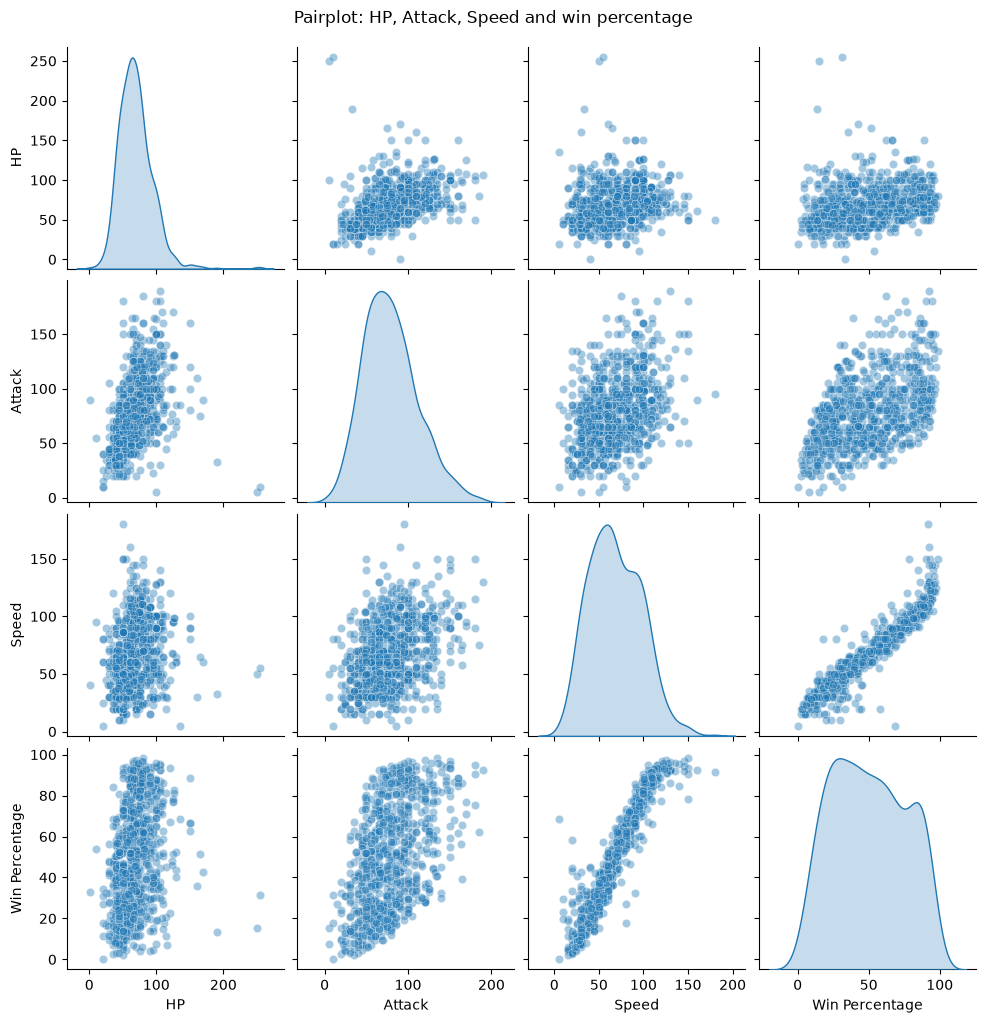

In [14]:
sns.pairplot(df[["HP", "Attack", "Speed", "Win Percentage"]], diag_kind="kde", plot_kws={"alpha": 0.4})
plt.suptitle("Pairplot: HP, Attack, Speed and win percentage", y=1.02)
plt.show()

**What I see:** the pairplot shows the same thing: Speed vs win percentage is a tight line, while HP and Attack vs win percentage are clouds. HP, Attack and Speed are also only loosely related to each other.

### 2.3 Top 10 Pokemon by win percentage

I analyze the top 10 Pokemon by win percentage and their stats.

In [15]:
top10 = df.sort_values("Win Percentage", ascending=False).head(10)
top10[["Name", "Type 1", "Type 2"] + stats + ["Legendary", "Total Fights", "Win Percentage"]]

,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Legendary,Total Fights,Win Percentage
154,Mega Aerodactyl,Rock,Flying,80,135,85,70,95,150,False,129.0,98.449612
512,Weavile,Dark,Ice,70,120,65,45,85,125,False,119.0,97.478992
703,Tornadus Therian Forme,Flying,None,79,100,80,110,90,121,True,125.0,96.800000
19,Mega Beedrill,Bug,Poison,65,150,40,15,80,145,False,119.0,96.638655
153,Aerodactyl,Rock,Flying,80,105,65,60,75,130,False,141.0,96.453901
476,Mega Lopunny,Normal,Fighting,65,136,94,54,96,135,False,129.0,96.124031
726,Greninja,Water,Dark,72,95,67,103,71,122,False,127.0,96.062992
716,Meloetta Pirouette Forme,Normal,Fighting,100,128,90,77,77,128,False,123.0,95.934959
164,Mega Mewtwo Y,Psychic,None,106,150,70,194,120,140,True,125.0,95.200000
349,Mega Sharpedo,Water,Dark,70,140,70,110,65,105,False,120.0,95.000000


**What I see:** the top 10 all win between 95% and 98.4% of their fights, with Mega Aerodactyl first (98.4%). All of them are fast (Speed 105–150), and most have a high Attack. Only 2 of them are Legendary (Tornadus Therian Forme and Mega Mewtwo Y), and 5 of them are Mega forms.

         Top 10 mean  All Pokemon mean  Difference
HP              78.7              69.1         9.6
Attack         125.9              78.9        47.0
Defense         72.6              73.9        -1.3
Sp. Atk         83.8              72.8        11.0
Sp. Def         85.4              72.0        13.4
Speed          130.1              68.4        61.7


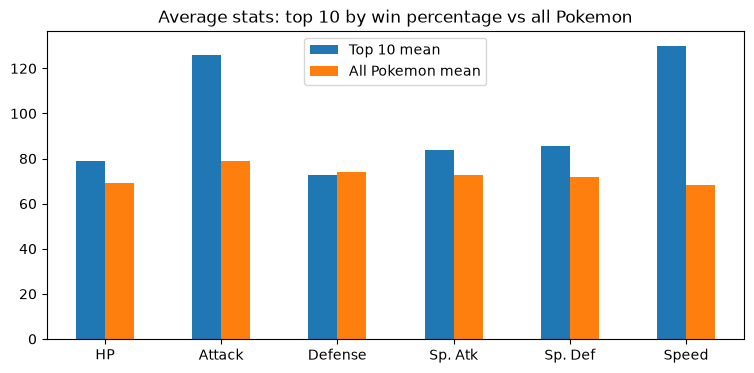

In [16]:
comparison = pd.DataFrame({
    "Top 10 mean": top10[stats].mean(),
    "All Pokemon mean": df[stats].mean(),
}).round(1)
comparison["Difference"] = comparison["Top 10 mean"] - comparison["All Pokemon mean"]
print(comparison)

comparison[["Top 10 mean", "All Pokemon mean"]].plot(kind="bar", figsize=(9, 4))
plt.title("Average stats: top 10 by win percentage vs all Pokemon")
plt.xticks(rotation=0)
plt.show()

**What I see:** the top 10 are much faster than the average Pokemon (Speed 130.1 vs 68.4, +61.7) and have a much higher Attack (125.9 vs 78.9, +47.0). Their Defense is not higher than average (72.6 vs 73.9). This again says that speed and attack matter for winning, and defense hardly does.

## 3. Machine Learning

- Split data into training/testing sets (80/20 split).
- Train and evaluate 3 regression models (for example, Linear Regression, Random Forest, XGBoost) to predict win percentage.
- Compare model performance using Mean Absolute Error (MAE).

### 3.1 Train/test split (80/20)

I split the data into training and testing sets with an 80/20 split.

In [17]:
features = stats + ["Generation", "Legendary"]
X = df[features].copy()
X["Legendary"] = X["Legendary"].astype(int)
# Legendary is True/False, I turn it into 1/0 so the models can use it
y = df["Win Percentage"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# 80% for training, 20% for testing, random_state=42 so I get the same split every time
print("Features:", features)
print("Train:", X_train.shape, " Test:", X_test.shape)

Features: ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed', 'Generation', 'Legendary']
Train: (627, 8)  Test: (157, 8)


**What I see:** I use 8 features (the six stats, Generation and Legendary as 0/1). 627 Pokemon are for training and 157 for testing (80/20). I don't need to scale the features for these models: Linear Regression gives the same predictions with or without scaling, and tree models don't care about scale.

### 3.2 Train and evaluate 3 regression models

I train and evaluate 3 regression models (for example, Linear Regression, Random Forest, and XGBoost) to predict win percentage.

If I use XGBoost, I may need to install it first in Colab with `%pip install xgboost`.

In [18]:
try:
    from xgboost import XGBRegressor
    third_name = "XGBoost"
    third_model = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
except ImportError:
    # if xgboost is not installed, I use scikit-learn's gradient boosting, which works the same way (boosted trees)
    from sklearn.ensemble import GradientBoostingRegressor
    third_name = "Gradient Boosting"
    third_model = GradientBoostingRegressor(random_state=42)

from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    third_name: third_model,
}

results = []
predictions = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    predictions[name] = pred
    cv_mae = -cross_val_score(m, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
    # 5-fold cross-validation on the training set, to check the result is not just one lucky split
    results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R2": r2_score(y_test, pred),
        "CV MAE (train, 5-fold)": cv_mae,
    })
    print(f"{name}: test MAE = {mean_absolute_error(y_test, pred):.2f} percentage points")

Linear Regression: test MAE = 6.23 percentage points


Random Forest: test MAE = 4.38 percentage points


XGBoost: test MAE = 4.48 percentage points


**What I see:** XGBoost was installed here, so I used it as my third model. The MAE is in **percentage points**: for example, an MAE of 4.38 means that on average the prediction is about 4.4 points away from the real win percentage.

### 3.3 Compare the models with MAE

I compare the model performance using Mean Absolute Error (MAE).

               Model  Test MAE  Test R2  CV MAE (train, 5-fold)
0      Random Forest     4.380    0.939                   4.369
1            XGBoost     4.485    0.943                   4.244
2  Linear Regression     6.227    0.873                   5.589


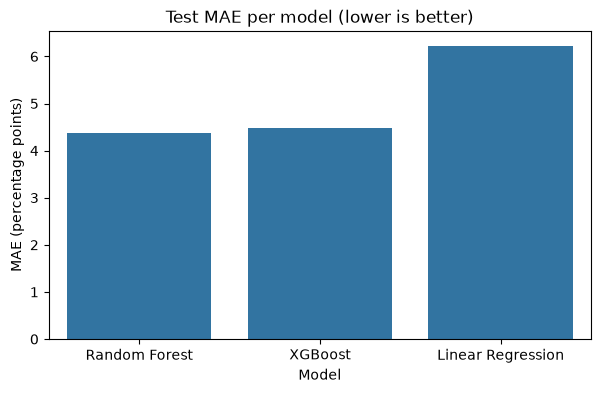

In [19]:
results_df = pd.DataFrame(results).sort_values("Test MAE").reset_index(drop=True).round(3)
print(results_df)

plt.figure(figsize=(7, 4))
sns.barplot(data=results_df, x="Model", y="Test MAE")
plt.title("Test MAE per model (lower is better)")
plt.ylabel("MAE (percentage points)")
plt.show()

**What I see:**
- **Random Forest** has the lowest test MAE (**4.38**), very close to **XGBoost** (**4.48**). XGBoost has a slightly lower cross-validation MAE (4.24 vs 4.37) and a slightly higher R² (0.943 vs 0.939), so the two tree models are practically tied.
- **Linear Regression** is clearly worse (MAE **6.23**, R² 0.873). A straight-line model cannot capture the curve at the very low and very high win percentages as well as the tree models.
- The cross-validation MAE of each model is close to its test MAE, so the results are not from one lucky split.

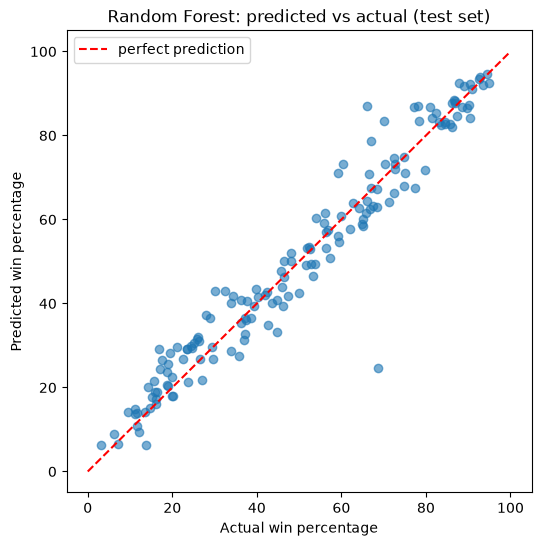

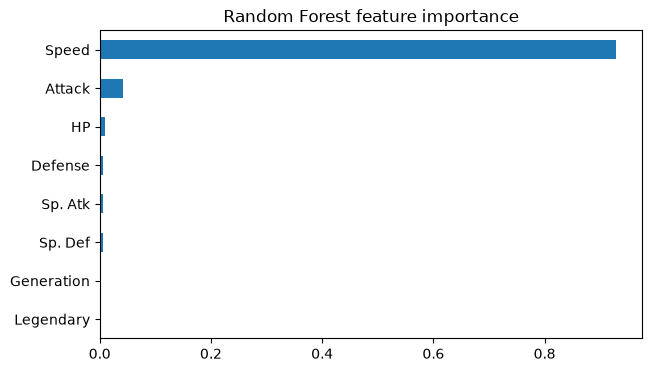

Speed         0.929
Attack        0.041
HP            0.009
Defense       0.007
Sp. Atk       0.006
Sp. Def       0.005
Generation    0.003
Legendary     0.000
dtype: float64


In [20]:
best_name = results_df.loc[0, "Model"]
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions[best_name], alpha=0.6)
plt.plot([0, 100], [0, 100], "r--", label="perfect prediction")
plt.xlabel("Actual win percentage")
plt.ylabel("Predicted win percentage")
plt.title(f"{best_name}: predicted vs actual (test set)")
plt.legend()
plt.show()

importances = pd.Series(models["Random Forest"].feature_importances_, index=features).sort_values()
importances.plot(kind="barh", figsize=(7, 4))
plt.title("Random Forest feature importance")
plt.show()
print(importances[::-1].round(3))

**What I see:** most points of the Random Forest are close to the red line, so the predictions are good for weak and strong Pokemon. There are a few bigger misses, for example one Pokemon that really wins about 69% and is predicted around 25%. The feature importance confirms the EDA: the forest uses **Speed** for about 93% of its decisions, then a little Attack (4%), and the other features hardly matter.

### 3.4 Extra: PCA (dimensionality reduction)

PCA is one of the things this challenge says I learn. I use it to see if the 6 battle stats can be squeezed into fewer "summary" columns, and how the win percentage looks on the first two of them.

Explained variance per component: [0.453 0.183 0.128 0.119 0.072 0.045]
Cumulative: [0.453 0.636 0.764 0.884 0.955 1.   ]


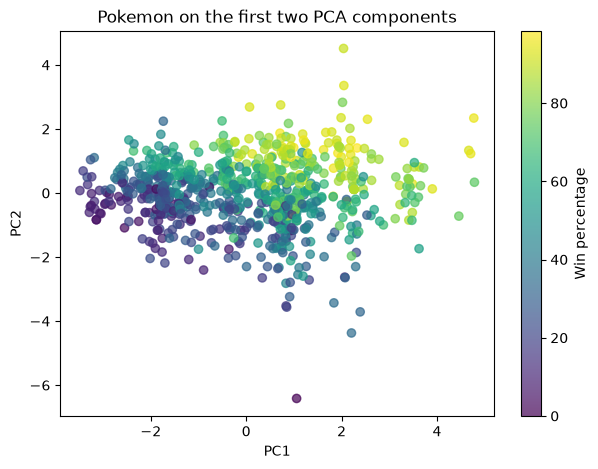

       HP  Attack  Defense  Sp. Atk  Sp. Def  Speed
PC1  0.39    0.44     0.36     0.46     0.45   0.34
PC2 -0.08    0.02    -0.63     0.31    -0.24   0.67


In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

stats_scaled = StandardScaler().fit_transform(df[stats])
# PCA needs the stats on the same scale
pca = PCA()
components = pca.fit_transform(stats_scaled)
print("Explained variance per component:", pca.explained_variance_ratio_.round(3))
print("Cumulative:", pca.explained_variance_ratio_.cumsum().round(3))

plt.figure(figsize=(7, 5))
sc = plt.scatter(components[:, 0], components[:, 1], c=df["Win Percentage"], cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="Win percentage")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Pokemon on the first two PCA components")
plt.show()
print(pd.DataFrame(pca.components_[:2], columns=stats, index=["PC1", "PC2"]).round(2))

**What I see:** the first component explains 45.3% of the variation in the six stats, and the first two together 63.6%. PC1 has positive weights on all six stats, so it is like an "overall strength" score. PC2 is mostly Speed (0.67) against Defense (-0.63), so it separates fast Pokemon from defensive ones. In the scatter plot, the high win percentages (yellow) are mostly in the upper right (higher PC1 and higher PC2, so strong and fast Pokemon), and the low ones (purple) are on the left. I would need 5 of the 6 components to keep 95% of the information, so PCA does not save much here, and since Speed alone explains most of the win percentage, I kept the original stats for the models.

## Conclusion

- I merged `pokemon.csv` (800 Pokemon) with `combats.csv` (50,000 battles), filled the one missing name with Primeape (the row at index 62, `#` 63, right after Mankey) and marked the 386 missing `Type 2` values as "None".
- I calculated the win percentage (wins / total fights × 100) for the 784 Pokemon that fought. 16 Pokemon never fought, so I left them out instead of giving them a wrong 0%.
- **Speed is the stat that decides battles in this dataset** (correlation 0.938 with the win percentage). Attack and Sp. Atk help a bit, Defense almost not at all. The top 10 Pokemon are very fast and have high Attack, and Legendary Pokemon win much more often on average.
- To predict the win percentage, **Random Forest (test MAE 4.38)** and **XGBoost (test MAE 4.48)** did best and are practically tied, and **Linear Regression (test MAE 6.23)** was clearly worse. So my best model predicts a Pokemon's win percentage within about 4.4 percentage points on average, using only its stats.